In [42]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv(r"C:\Users\rauna\OneDrive\Desktop\MLProject\data\online_retail_working.csv")


In [6]:
df


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
1027012,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
1027013,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1027014,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1027015,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [14]:

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("Data type:", df['InvoiceDate'].dtype)
print("Earliest transaction:", df['InvoiceDate'].min())
print("Latest transaction:", df['InvoiceDate'].max())
print(
    "Total days covered:",
    (df['InvoiceDate'].max() - df['InvoiceDate'].min()).days
)


Data type: datetime64[ns]
Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00
Total days covered: 738


In [16]:

print("Date range:")
print(df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())

print("\nRecords per year:")
print(df['InvoiceDate'].dt.year.value_counts().sort_index())

print("\nTotal days:")
print((df['InvoiceDate'].max() - df['InvoiceDate'].min()).days)


Date range:
2009-12-01 07:45:00 to 2011-12-09 12:50:00

Records per year:
InvoiceDate
2009     44466
2010    490131
2011    492420
Name: count, dtype: int64

Total days:
738


In [18]:

cutoff_date = pd.Timestamp('2011-09-10')

observation_start = pd.Timestamp('2009-12-01')
prediction_end = cutoff_date + pd.Timedelta(days=90)

print("Observation period:", observation_start.date(), "to", (cutoff_date - pd.Timedelta(days=1)).date())
print("Prediction period:", cutoff_date.date(), "to", (prediction_end - pd.Timedelta(days=1)).date())


Observation period: 2009-12-01 to 2011-09-09
Prediction period: 2011-09-10 to 2011-12-08


In [20]:

df_purchase = df[
    (~df['Invoice'].astype(str).str.startswith('C')) &
    (df['Quantity'] > 0) &
    (df['Price'] > 0) &
    (df['Customer ID'].notna())
].copy()

print("Original dataset:", df.shape)
print("Paid purchase dataset:", df_purchase.shape)
print("Unique customers:", df_purchase['Customer ID'].nunique())


Original dataset: (1027017, 9)
Paid purchase dataset: (779425, 9)
Unique customers: 5878


In [22]:

# Historical transactions: used for feature creation
df_observation = df_purchase[
    df_purchase['InvoiceDate'] < cutoff_date
].copy()

# Future transactions: used for target creation
df_future = df_purchase[
    (df_purchase['InvoiceDate'] >= cutoff_date) &
    (df_purchase['InvoiceDate'] < prediction_end)
].copy()

print("Observation records:", len(df_observation))
print("Future records:", len(df_future))

print("\nUnique historical customers:", df_observation['Customer ID'].nunique())
print("Unique future customers:", df_future['Customer ID'].nunique())


Observation records: 620572
Future records: 158242

Unique historical customers: 5281
Unique future customers: 2886


In [24]:

# Calculate total value of each customer's invoice
df_invoice = (
    df_observation
    .groupby(['Customer ID', 'Invoice'])
    .agg(
        InvoiceAmount=('TotalAmount', 'sum'),
        InvoiceDate=('InvoiceDate', 'max')
    )
    .reset_index()
)

df_invoice.head()


,Customer ID,Invoice,InvoiceAmount,InvoiceDate
0,12346.0,491725,45.0,2009-12-14 08:34:00
1,12346.0,491742,22.5,2009-12-14 11:00:00
2,12346.0,491744,22.5,2009-12-14 11:02:00
3,12346.0,492718,22.5,2009-12-18 10:47:00
4,12346.0,492722,1.0,2009-12-18 10:55:00


In [26]:

reference_date = cutoff_date

customer_features = (
    df_invoice
    .groupby('Customer ID')
    .agg(
        LastPurchaseDate=('InvoiceDate', 'max'),
        Frequency=('Invoice', 'nunique'),
        Monetary=('InvoiceAmount', 'sum'),
        AverageOrderValue=('InvoiceAmount', 'mean')
    )
    .reset_index()
)

# Recency: days since the last purchase before the cutoff
customer_features['Recency'] = (
    reference_date - customer_features['LastPurchaseDate']
).dt.days

customer_features.head(10)


,Customer ID,LastPurchaseDate,Frequency,Monetary,AverageOrderValue,Recency
0,12346.0,2011-01-18 10:01:00,12,77556.46,6463.038333,234
1,12347.0,2011-08-02 08:48:00,6,3402.39,567.065000,38
2,12348.0,2011-04-05 10:47:00,4,1709.40,427.350000,157
3,12349.0,2010-10-28 08:23:00,3,2671.14,890.380000,316
4,12350.0,2011-02-02 16:01:00,1,334.40,334.400000,219
5,12351.0,2010-11-29 15:23:00,1,300.93,300.930000,284
6,12352.0,2011-03-22 16:08:00,7,1905.61,272.230000,171
7,12353.0,2011-05-19 17:47:00,2,406.76,203.380000,113
8,12354.0,2011-04-21 13:11:00,1,1079.40,1079.400000,141
9,12355.0,2011-05-09 13:49:00,2,947.61,473.805000,123


In [28]:

# Identify customers who purchased during the future 90-day period
future_customers = df_future['Customer ID'].unique()

# Create binary target
customer_features['RepeatPurchase_90D'] = (
    customer_features['Customer ID'].isin(future_customers).astype(int)
)

customer_features.head(10)


,Customer ID,LastPurchaseDate,Frequency,Monetary,AverageOrderValue,Recency,RepeatPurchase_90D
0,12346.0,2011-01-18 10:01:00,12,77556.46,6463.038333,234,0
1,12347.0,2011-08-02 08:48:00,6,3402.39,567.065000,38,1
2,12348.0,2011-04-05 10:47:00,4,1709.40,427.350000,157,1
3,12349.0,2010-10-28 08:23:00,3,2671.14,890.380000,316,1
4,12350.0,2011-02-02 16:01:00,1,334.40,334.400000,219,0
5,12351.0,2010-11-29 15:23:00,1,300.93,300.930000,284,0
6,12352.0,2011-03-22 16:08:00,7,1905.61,272.230000,171,1
7,12353.0,2011-05-19 17:47:00,2,406.76,203.380000,113,0
8,12354.0,2011-04-21 13:11:00,1,1079.40,1079.400000,141,0
9,12355.0,2011-05-09 13:49:00,2,947.61,473.805000,123,0


Target distribution:
RepeatPurchase_90D
0    2991
1    2290
Name: count, dtype: int64

Target percentage:
RepeatPurchase_90D
0    56.64
1    43.36
Name: proportion, dtype: float64


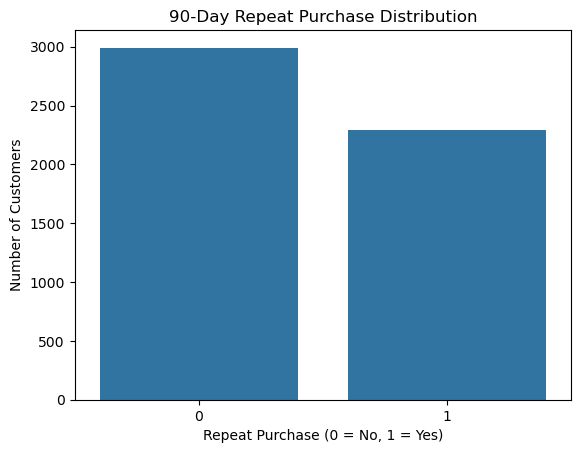

In [30]:

# Count customers in each target class
target_counts = customer_features['RepeatPurchase_90D'].value_counts().sort_index()

print("Target distribution:")
print(target_counts)

print("\nTarget percentage:")
print(
    customer_features['RepeatPurchase_90D']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

# Visualise the target distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=customer_features,
    x='RepeatPurchase_90D'
)

plt.title('90-Day Repeat Purchase Distribution')
plt.xlabel('Repeat Purchase (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()


In [32]:

print("Dataset shape:", customer_features.shape)

print("\nColumn information:")
customer_features.info()

print("\nMissing values:")
print(customer_features.isnull().sum())

print("\nDuplicate customer IDs:")
print(customer_features['Customer ID'].duplicated().sum())

print("\nDescriptive statistics:")
display(customer_features.describe())


Dataset shape: (5281, 7)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5281 entries, 0 to 5280
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Customer ID         5281 non-null   float64       
 1   LastPurchaseDate    5281 non-null   datetime64[ns]
 2   Frequency           5281 non-null   int64         
 3   Monetary            5281 non-null   float64       
 4   AverageOrderValue   5281 non-null   float64       
 5   Recency             5281 non-null   int64         
 6   RepeatPurchase_90D  5281 non-null   int32         
dtypes: datetime64[ns](1), float64(3), int32(1), int64(2)
memory usage: 268.3 KB

Missing values:
Customer ID           0
LastPurchaseDate      0
Frequency             0
Monetary              0
AverageOrderValue     0
Recency               0
RepeatPurchase_90D    0
dtype: int64

Duplicate customer IDs:
0

Descriptive statistics:


,Customer ID,LastPurchaseDate,Frequency,Monetary,AverageOrderValue,Recency,RepeatPurchase_90D
count,5281.000000,5281,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000
mean,15324.100170,2011-02-14 17:34:20.109827584,5.745692,2637.863286,369.292417,206.814240,0.433630
min,12346.000000,2009-12-01 09:55:00,1.000000,2.900000,2.900000,0.000000,0.000000
25%,13850.000000,2010-10-18 15:37:00,1.000000,318.240000,174.668000,49.000000,0.000000
50%,15313.000000,2011-03-30 11:04:00,3.000000,783.580000,276.860000,163.000000,0.000000
75%,16807.000000,2011-07-22 13:53:00,6.000000,2078.540000,409.725000,326.000000,1.000000
max,18287.000000,2011-09-09 15:53:00,309.000000,456780.490000,14844.766667,647.000000,1.000000
std,1712.323865,NaN,11.464582,12225.544955,538.206215,175.029112,0.495622


In [34]:

# Additional customer behaviour features
additional_features = (
    df_observation
    .groupby('Customer ID')
    .agg(
        ProductDiversity=('StockCode', 'nunique')
    )
    .reset_index()
)

# Calculate total quantity per invoice first
invoice_quantity = (
    df_observation
    .groupby(['Customer ID', 'Invoice'])
    .agg(TotalItems=('Quantity', 'sum'))
    .reset_index()
)

# Average items per order for each customer
avg_items = (
    invoice_quantity
    .groupby('Customer ID')
    .agg(AvgItemsPerOrder=('TotalItems', 'mean'))
    .reset_index()
)

# Add both features to our customer dataset
customer_features = customer_features.merge(
    additional_features, on='Customer ID', how='left'
)

customer_features = customer_features.merge(
    avg_items, on='Customer ID', how='left'
)

display(customer_features.head())


,Customer ID,LastPurchaseDate,Frequency,Monetary,AverageOrderValue,Recency,RepeatPurchase_90D,ProductDiversity,AvgItemsPerOrder
0,12346.0,2011-01-18 10:01:00,12,77556.46,6463.038333,234,0,27,6190.416667
1,12347.0,2011-08-02 08:48:00,6,3402.39,567.065000,38,1,107,349.833333
2,12348.0,2011-04-05 10:47:00,4,1709.40,427.350000,157,1,25,624.250000
3,12349.0,2010-10-28 08:23:00,3,2671.14,890.380000,316,1,90,331.000000
4,12350.0,2011-02-02 16:01:00,1,334.40,334.400000,219,0,17,197.000000


In [36]:

# Input features
feature_cols = [
    'Recency',
    'Frequency',
    'Monetary',
    'AverageOrderValue',
    'ProductDiversity',
    'AvgItemsPerOrder'
]

X = customer_features[feature_cols].copy()

# Target variable
y = customer_features['RepeatPurchase_90D'].copy()

print("Feature matrix (X):", X.shape)
print("Target variable (y):", y.shape)

display(X.head())


Feature matrix (X): (5281, 6)
Target variable (y): (5281,)


,Recency,Frequency,Monetary,AverageOrderValue,ProductDiversity,AvgItemsPerOrder
0,234,12,77556.46,6463.038333,27,6190.416667
1,38,6,3402.39,567.065000,107,349.833333
2,157,4,1709.40,427.350000,25,624.250000
3,316,3,2671.14,890.380000,90,331.000000
4,219,1,334.40,334.400000,17,197.000000


,count,mean,std,min,25%,50%,75%,max
Recency,5281.0,206.814240,175.029112,0.0,49.000,163.00,326.000,647.000000
Frequency,5281.0,5.745692,11.464582,1.0,1.000,3.00,6.000,309.000000
Monetary,5281.0,2637.863286,12225.544955,2.9,318.240,783.58,2078.540,456780.490000
AverageOrderValue,5281.0,369.292417,538.206215,2.9,174.668,276.86,409.725,14844.766667
ProductDiversity,5281.0,74.356751,104.968606,1.0,18.000,41.00,92.000,2182.000000
AvgItemsPerOrder,5281.0,241.689115,1400.038545,1.0,87.000,148.00,251.000,87167.000000



Feature Skewness:


AvgItemsPerOrder     51.748198
Monetary             23.761168
AverageOrderValue    13.652309
Frequency            11.070624
ProductDiversity      6.120714
Recency               0.665248
dtype: float64

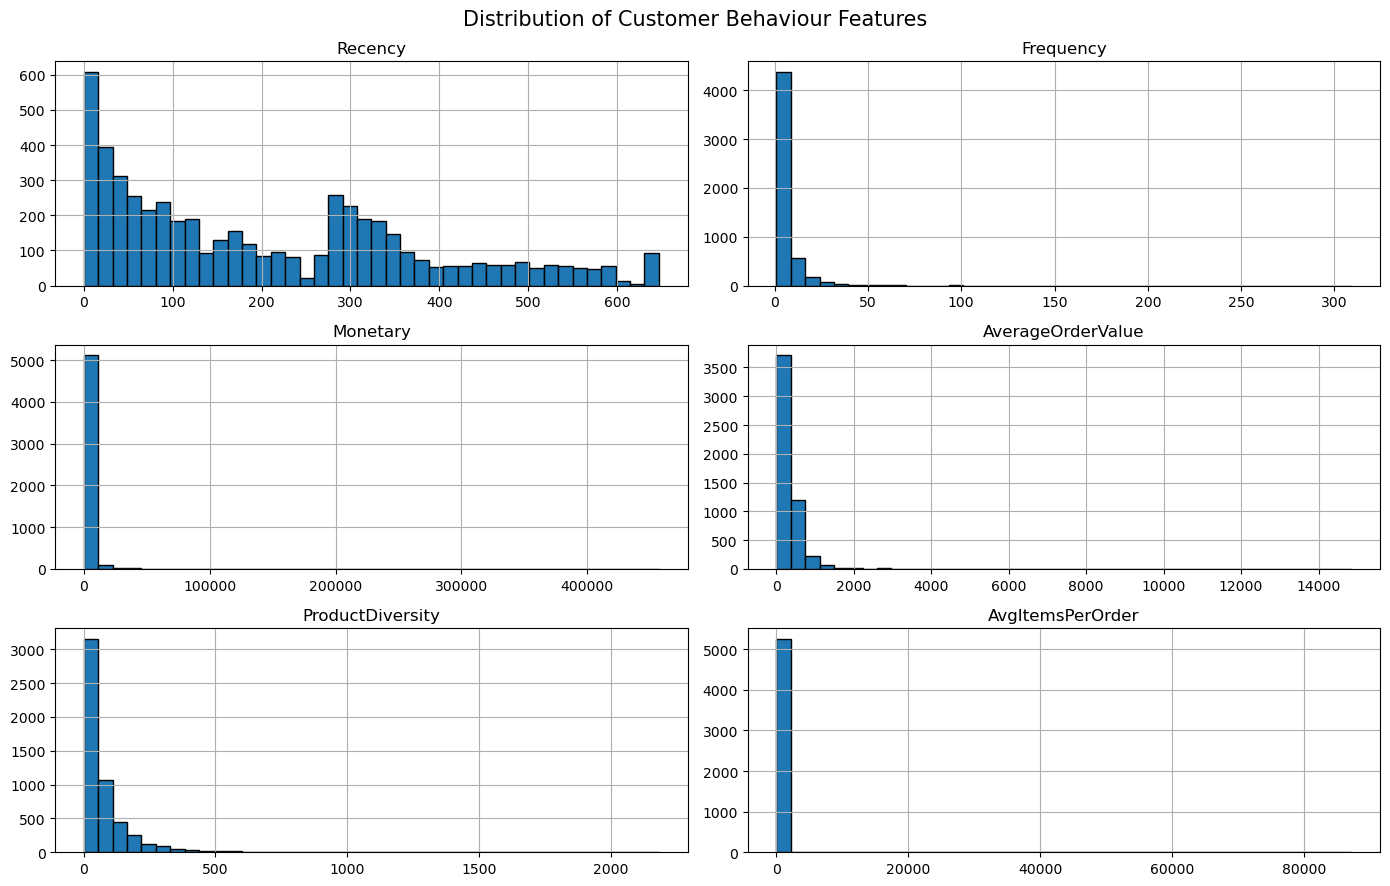

In [38]:

# Summary statistics of model features
display(X.describe().T)

# Skewness of each feature
print("\nFeature Skewness:")
display(X.skew().sort_values(ascending=False))

# Histograms
X.hist(
    figsize=(14, 9),
    bins=40,
    edgecolor='black'
)

plt.suptitle('Distribution of Customer Behaviour Features', fontsize=15)
plt.tight_layout()
plt.show()


In [44]:

# Copy original features
X_transformed = X.copy()

# Features selected for log transformation
log_cols = [
    'Frequency',
    'Monetary',
    'AverageOrderValue',
    'ProductDiversity',
    'AvgItemsPerOrder'
]

# Apply log1p transformation
for col in log_cols:
    X_transformed[col] = np.log1p(X_transformed[col])

# Compare skewness
skew_comparison = pd.DataFrame({
    'Before': X.skew(),
    'After': X_transformed.skew()
})

display(skew_comparison.round(3))


,Before,After
Recency,0.665,0.665
Frequency,11.071,1.058
Monetary,23.761,0.285
AverageOrderValue,13.652,-0.021
ProductDiversity,6.121,-0.275
AvgItemsPerOrder,51.748,-0.649


In [46]:

print("Feature ranges after log transformation:\n")

display(pd.DataFrame({
    'Minimum': X_transformed.min(),
    'Maximum': X_transformed.max(),
    'Mean': X_transformed.mean(),
    'Standard Deviation': X_transformed.std()
}).round(3))


Feature ranges after log transformation:



,Minimum,Maximum,Mean,Standard Deviation
Recency,0.000,647.000,206.814,175.029
Frequency,0.693,5.737,1.494,0.786
Monetary,1.361,13.032,6.735,1.367
AverageOrderValue,1.361,9.605,5.606,0.738
ProductDiversity,0.693,7.688,3.684,1.195
AvgItemsPerOrder,0.693,11.376,4.963,0.945



## Feature Engineering and Feature Transformation

### 1. Objective
The objective is to predict whether an existing customer will make at least one paid purchase within the next 90 days. This is a supervised binary classification problem.

### 2. Observation and Prediction Windows
- **Observation period:** 1 December 2009 – 9 September 2011.
- **Prediction period:** 10 September 2011 – 8 December 2011 (90 days).
- Historical transactions were used to construct input features (X).
- Future transactions were used exclusively to construct the target variable (y).

### 3. Purchase Data Preparation
Created a separate modelling dataset by excluding:
- Cancellation invoices (invoice numbers starting with C).
- Transactions with non-positive quantities.
- Transactions with non-positive prices.
- Transactions without Customer IDs.

### 4. Customer-Level Feature Engineering
Converted transaction-level records into invoice-level and then customer-level records.

Created the following features:

| Feature | Description |
|---|---|
| Recency | Days since the customer's last purchase before the cutoff date. |
| Frequency | Number of unique historical invoices. |
| Monetary | Total historical spending by the customer. |
| AverageOrderValue | Average value of the customer's invoices. |
| ProductDiversity | Number of unique products purchased. |
| AvgItemsPerOrder | Average quantity of items per invoice. |

### 5. Target Variable Creation
Created `RepeatPurchase_90D` using future transactions:
- `1` – Customer made at least one paid purchase during the next 90 days.
- `0` – Customer made no paid purchase during the next 90 days.

### 6. Feature Selection
Separated the dataset into:
- `X` – Six customer behaviour features.
- `y` – Binary target variable.

Excluded Customer ID and LastPurchaseDate from the model input features.

### 7. Feature Distribution Analysis
- Examined descriptive statistics, histograms and skewness.
- Identified substantial right skewness in Frequency, Monetary, AverageOrderValue, ProductDiversity and AvgItemsPerOrder.
- Recency showed moderate skewness.

### 8. Log Transformation
Applied `np.log1p()` to five features:
- Frequency
- Monetary
- AverageOrderValue
- ProductDiversity
- AvgItemsPerOrder

Recency was retained without transformation.

Compared skewness before and after transformation. The transformation substantially reduced skewness across the five selected features.

### 9. Scaling Investigation
Inspected feature ranges, means and standard deviations after log transformation.

Identified StandardScaler as a suitable candidate for scale-sensitive algorithms such as Logistic Regression, KNN and SVM.

**Note:** Log transformation was explored on the current dataset. Final preprocessing will be fitted using training data only to prevent data leakage.



## Next Steps: Model Preparation and Training

### 1. Train-Test Split
- Split the dataset into 80% training and 20% testing.
- Use stratified sampling to maintain the target class proportions.
- Keep the test set separate for final model evaluation.

### 2. Feature Scaling
- Apply StandardScaler to scale numerical features.
- Fit the scaler only on the training data.
- Transform both training and testing data using the fitted scaler.
- Use preprocessing pipelines to prevent data leakage during model training and cross-validation.

### 3. Baseline Model
- Establish a simple baseline using DummyClassifier.
- Compare actual model performance against this baseline.

### 4. Model Training
Train and compare suitable classification algorithms:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)

### 5. Model Evaluation
Evaluate models using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC

Pay particular attention to Recall and F1-score when evaluating repeat-purchase prediction.

### 6. Model Comparison and Tuning
- Compare model performance.
- Identify the most suitable algorithm.
- Perform hyperparameter tuning using cross-validation.
- Evaluate the selected model on the untouched test set.

### 7. Feature Importance and Interpretation
- Identify which customer behaviour features contribute most to predictions.
- Interpret the factors associated with repeat purchasing.

### 8. Final Project Deliverables
- Final trained model.
- Model evaluation and comparison.
- Visualizations and performance analysis.
- Research report and GitHub documentation.
